# Responses, target-aligned → `responses_aligned.pdf`

Every completed response, rotated so the cued object sits at the same place on the ring.
One column per monkey, 1-object trials on top and 2-object below, colored by whether the
response landed within `CORRECT_THRESHOLD` of the target. Each panel carries its trial
count and its success rate.

That post-hoc criterion is scored offline from the stored response endpoint, and so differs
slightly from the reward the monkey actually received online — the saccade detection behind
the stored endpoint is a little better than the one the task ran under real-time constraints.
The two labels are compared below; they agree on ~99% of the trials plotted here.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import common
import config

common.set_style()

FIGSIZE = (4.2, 4.4)
OUTPUT = 'responses_aligned.pdf'
VIEW = 0.5              # half-width of each panel, in data units
MIN_RESPONSE_R = config.MIN_RESPONSE_R   # uncommitted responses, from ../config.py
CORRECT_THRESHOLD = config.REWARD_THRESHOLD   # 0.2, the post-hoc on-target criterion
GREEN, RED = '#2ca02c', '#d62728'

In [2]:
# `correct` is scored here as a post-hoc criterion — the response endpoint landed within
# CORRECT_THRESHOLD (0.2, in display units) of the cued object — rather than read from the
# reward the task delivered. The two are not identical: the online reward window was applied
# to the running eye trace under real-time constraints, whereas the stored response endpoint
# comes from a slightly better offline saccade detection, so a few trials were rewarded at an
# endpoint that is in fact off-target, and a few on-target responses went unrewarded because
# the landing was not detected in time. `add_correct` keeps the recorded reward as `rewarded`
# so the disagreement can be quantified: over the 28,133 trials plotted the two labels agree
# on 99.41% (40 correct-but-unrewarded, 126 rewarded-but-not-correct). Agreement is highest on
# 1-object trials (99.8%) and lowest on Monkey E's 2-object trials (99.2%). Printed below and
# per panel, so the numbers stay current if the data or the threshold change.
ring = common.add_correct(common.load_ring(), threshold=CORRECT_THRESHOLD)
kept = ring[ring['response_r'] >= MIN_RESPONSE_R].copy()
print(f'{int((kept["completed"] == True).sum()):,} of '
      f'{int((ring["completed"] == True).sum()):,} completed trials kept '
      f'(response radius >= {MIN_RESPONSE_R})')

radius = common.ring_radius(ring)
rows = [('1-object', common.prep_1obj(kept), 'object_0_theta'),
        ('2-object', common.prep_2obj(kept), 'target_theta')]

n, agree, correct_only, rewarded_only = common.correct_vs_reward(
    pd.concat([data for _, data, _ in rows]))
print(f'\npost-hoc correct (<{CORRECT_THRESHOLD}) vs. delivered reward, over the {n:,} '
      f'trials plotted:\n  agree on {100 * agree:.2f}% ({n - correct_only - rewarded_only:,} '
      f'of {n:,});  {correct_only:,} correct but unrewarded, '
      f'{rewarded_only:,} rewarded but not correct')

29,674 of 30,300 completed trials kept (response radius >= 0.25)

post-hoc correct (<0.2) vs. delivered reward, over the 28,133 trials plotted:
  agree on 99.41% (27,967 of 28,133);  40 correct but unrewarded, 126 rewarded but not correct


Monkey P, 1-object: 2,611 correct / 107 not  (96.1%)   [vs. reward: 99.85% agree, +4 / -0]
Monkey E, 1-object: 2,793 correct / 106 not  (96.3%)   [vs. reward: 99.79% agree, +4 / -2]
Monkey P, 2-object: 9,207 correct / 888 not  (91.2%)   [vs. reward: 99.44% agree, +12 / -45]
Monkey E, 2-object: 9,488 correct / 2,933 not  (76.4%)   [vs. reward: 99.20% agree, +20 / -79]
saved responses_aligned.pdf


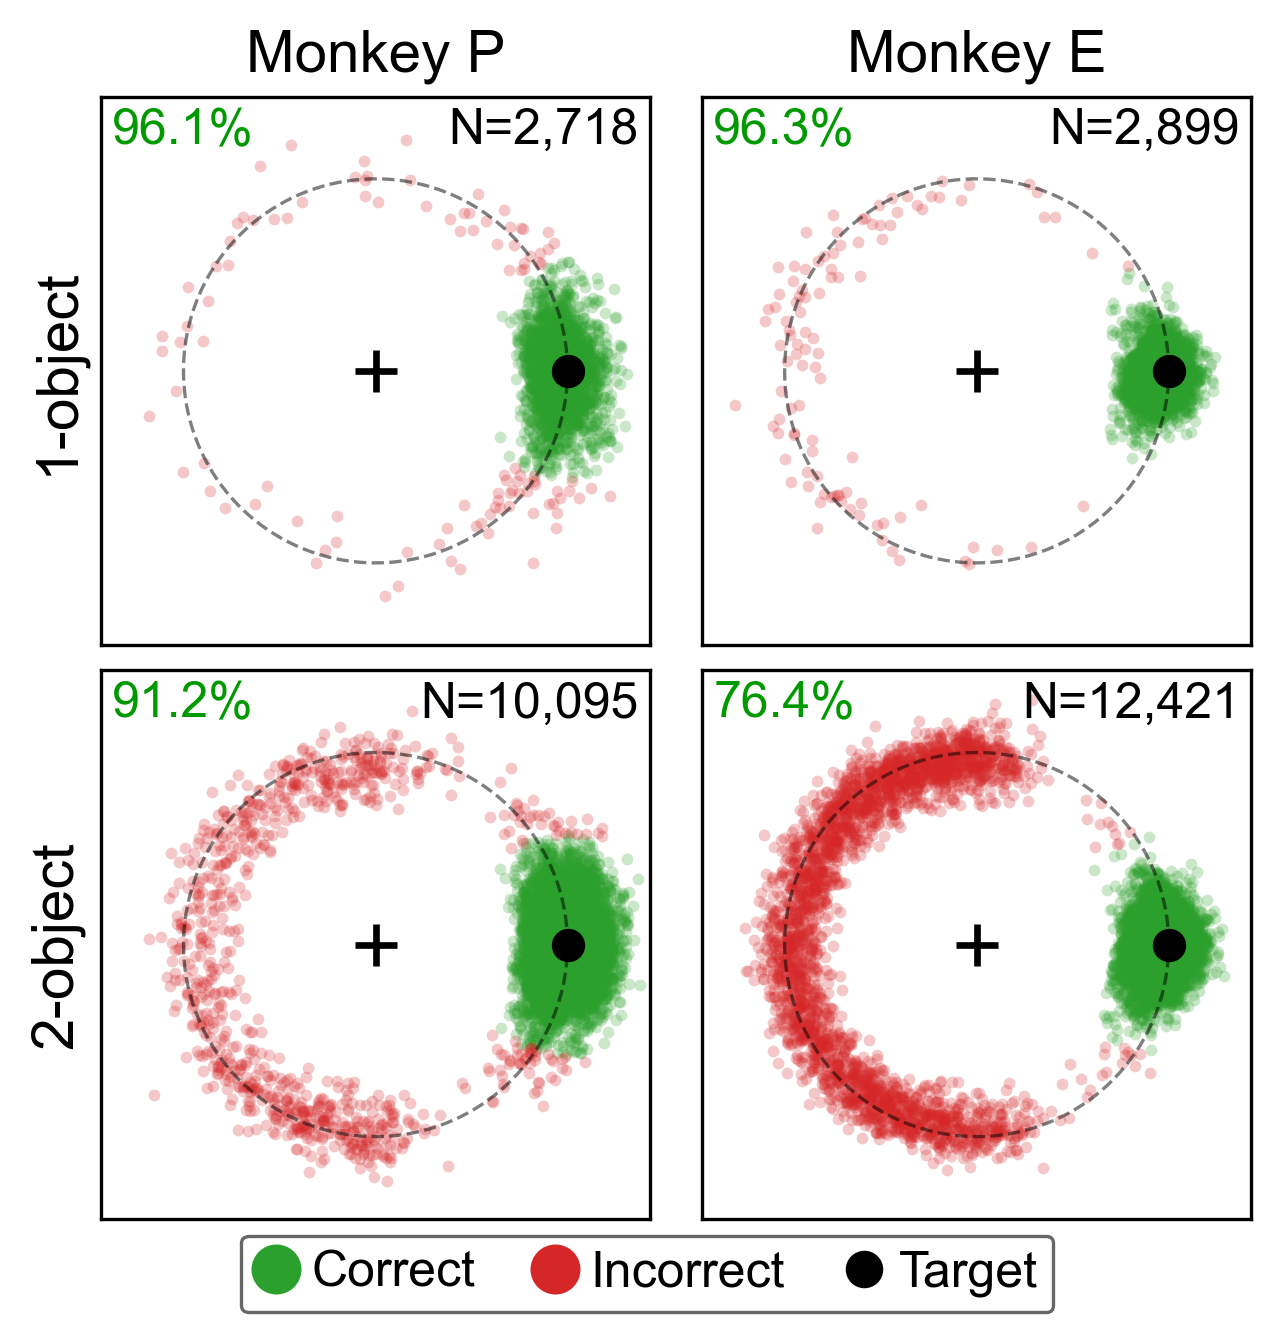

In [3]:
fig, axes = plt.subplots(2, len(common.SUBJECTS), figsize=FIGSIZE, squeeze=False,
                         layout='constrained')
fig.get_layout_engine().set(rect=(0, 0.08, 1, 0.92), wspace=0.02)   # band for the legend

for i_row, (kind, data, cued_col) in enumerate(rows):
    for ax, subject in zip(axes[i_row], common.SUBJECTS):
        trials = data[data['subject'] == subject]
        aligned = trials['response_theta'].values - trials[cued_col].values
        r = trials['response_r'].values
        correct = np.asarray(trials['correct'].values, bool)

        common.draw_ring(ax, radius)
        for is_correct, color in [(True, GREEN), (False, RED)]:
            m = correct == is_correct
            ax.scatter(r[m] * np.cos(aligned[m]), r[m] * np.sin(aligned[m]),
                       s=8, alpha=0.25, linewidths=0, color=color)
        ax.plot(radius, 0, marker='o', color='k', markersize=7, zorder=5)

        ax.text(0.98, 0.98, f'N={len(r):,}', transform=ax.transAxes, ha='right', va='top',
                fontsize=12)
        ax.text(0.02, 0.98, f'{100 * correct.mean():.1f}%', transform=ax.transAxes,
                ha='left', va='top', fontsize=12, color=(0.0, 0.6, 0.0))
        common.clean_square(ax, VIEW)
        if i_row == 0:
            ax.set_title(common.SUBJECT_LABELS[subject])
        # Per panel: the plotted post-hoc label, then how it compares with the reward the
        # animal was actually given online (they differ on a handful of near-boundary trials).
        _, agree, correct_only, rewarded_only = common.correct_vs_reward(trials)
        print(f'{common.SUBJECT_LABELS[subject]}, {kind}: {int(correct.sum()):,} correct / '
              f'{int((~correct).sum()):,} not  ({100 * correct.mean():.1f}%)'
              f'   [vs. reward: {100 * agree:.2f}% agree, '
              f'+{correct_only:,} / -{rewarded_only:,}]')
    axes[i_row][0].set_ylabel(kind, fontsize=14, labelpad=4)

common.boxed_legend(fig,
                    [common.legend_dot(GREEN, 12), common.legend_dot(RED, 12),
                     common.legend_dot('k', 9)],
                    ['Correct', 'Incorrect', 'Target'],
                    loc='lower center', bbox_to_anchor=(0.5, 0.0))
common.save(fig, OUTPUT)
plt.show()